# 03. Customer risk analysis

Turns the model into decisions: churn probability for every customer, value at risk, risk bands, value tiers, retention actions, expected benefit and the priority call list.

In [1]:
import sys
sys.path.insert(0, '../python')          # reusable code lives in /python
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from data_preprocessing import get_clean_data
from model_training import train_and_compare
from model_evaluation import evaluate, RETENTION_COST, SAVE_RATE
import customer_scoring as cs

## 1. Score all customers

Each customer is scored by a model that never saw that customer in training (5-fold out-of-fold calibrated probabilities), so the scores are honest. Value at risk = churn probability x customer value.

In [2]:
_, df = get_clean_data()
res = train_and_compare(df)
thr = evaluate(res)['threshold']
scored, auc = cs.score_customers(df, res, thr)
print(f'Out-of-fold ROC-AUC: {auc:.4f}')
print(f'Value at risk: {scored.Value_At_Risk.sum():,.0f}')
print(f"Customers worth contacting: {(scored.Contact_Recommended == 'Yes').sum()}")

Out-of-fold ROC-AUC: 0.9852
Value at risk: 57,293
Customers worth contacting: 315


## 2. Risk bands

High: probability 0.5 or more. Medium: 0.2 to 0.5. Low: below 0.2.

In [3]:
seg = cs.risk_segments(scored)
seg

,Risk_Band,Customers,Total_Value,Value_At_Risk,Actual_Churn_Rate_pct,High-Value,Mid-Value,Standard
0,High,424,53099.0,46821.1,88.7,4,58,362
1,Medium,150,16944.8,5391.6,32.0,0,16,134
2,Low,2276,1283678.8,5080.2,1.0,566,781,929


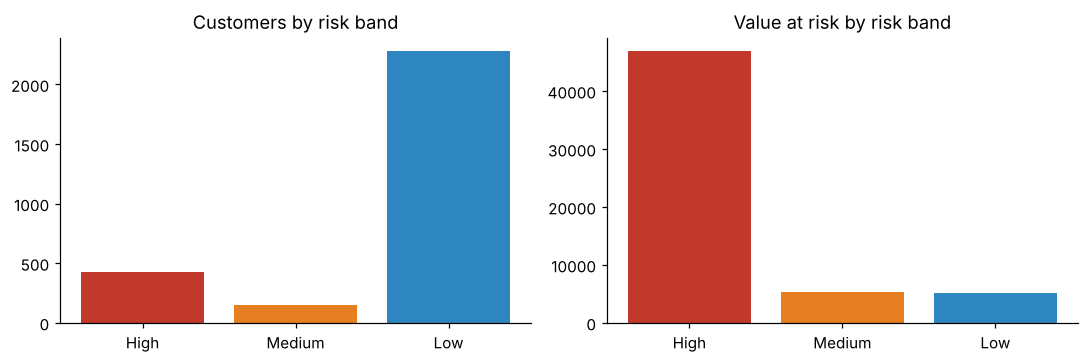

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(seg.Risk_Band, seg.Customers, color=['#C0392B', '#E67E22', '#2E86C1']); axes[0].set_title('Customers by risk band')
axes[1].bar(seg.Risk_Band, seg.Value_At_Risk, color=['#C0392B', '#E67E22', '#2E86C1']); axes[1].set_title('Value at risk by risk band')
plt.tight_layout(); plt.show()

The High band is 15% of customers but holds about 82% of the value at risk, so the retention team can concentrate on a small group.

## 3. Risk x value matrix

In [5]:
m = pd.crosstab(scored.Risk_Band, scored.Value_Tier).reindex(index=['High','Medium','Low'], columns=['High-Value','Mid-Value','Standard'], fill_value=0)
m['Total'] = m.sum(axis=1); m.loc['Total'] = m.sum(); m

Value_Tier,High-Value,Mid-Value,Standard,Total
Risk_Band,,,,
High,4,58,362,424
Medium,0,16,134,150
Low,566,781,929,2276
Total,570,855,1425,2850


## 4. Retention actions and expected benefit

Expected retention benefit = value at risk x 0.40 - 20. Actions 1 to 3 have a positive benefit; action 4 is handled by automated messages; action 5 means normal service.

In [6]:
rec = cs.retention_recommendations(scored)
rec

,Retention_Action,Rule,Customers,Value_At_Risk,Expected_Benefit,What_The_Team_Does,Priority
0,1 - Personal call + best offer,High risk and High-Value,4,2959.0,1104.0,Account manager calls with the strongest offer,Immediate
1,2 - Targeted discount / SMS offer,"High risk, other tiers",420,43862.0,9145.0,"Targeted discount or SMS offer, tested against...",This week
2,3 - Proactive check-in,"Medium risk, Mid or High value",16,1651.0,340.0,Light contact to understand problems before th...,This month
3,4 - Automated nurture,"Medium risk, Standard value",134,3741.0,-1184.0,"Automated messages only, no manual cost",Automated
4,5 - Normal service,Low risk,2276,5080.0,-43488.0,No action; contacting costs more than it saves,None


## 5. Priority call list (top 20 by value at risk)

In [7]:
scored[['Priority_Rank','CustomerID','Customer_Value','Churn_Probability','Value_At_Risk','Risk_Band','Retention_Action']].head(20).reset_index(drop=True)

,Priority_Rank,CustomerID,Customer_Value,Churn_Probability,Value_At_Risk,Risk_Band,Retention_Action
0,1,C0687,978.390,0.8673,848.56,High,1 - Personal call + best offer
1,2,C0389,987.255,0.8581,847.16,High,1 - Personal call + best offer
2,3,C1048,909.135,0.7073,643.03,High,1 - Personal call + best offer
3,4,C0955,929.295,0.6678,620.58,High,1 - Personal call + best offer
4,5,C0835,858.280,0.6363,546.12,High,2 - Targeted discount / SMS offer
5,6,C1523,487.170,1.0000,487.17,High,2 - Targeted discount / SMS offer
6,7,C0025,383.220,1.0000,383.22,High,2 - Targeted discount / SMS offer
7,8,C1034,363.060,1.0000,363.06,High,2 - Targeted discount / SMS offer
8,9,C1619,386.820,0.9364,362.22,High,2 - Targeted discount / SMS offer
9,10,C0986,337.725,1.0000,337.72,High,2 - Targeted discount / SMS offer


## 6. Save outputs

In [8]:
scored.to_csv('../data/processed/churn_scored.csv', index=False)
seg.to_csv('../results/customer_risk_segments.csv', index=False)
rec.to_csv('../results/retention_recommendations.csv', index=False)
print('Saved scored dataset and results')

Saved scored dataset and results
